# DBSCAN (Density-Based Spatial Clustering of Applications with Noise)

DBSCAN is an unsupervised clustering algorithm that groups data points based on their density. It identifies clusters of closely packed points while classifying points in low-density regions as noise or outliers.

## How It Works
1. Select a point and examine its neighbourhood within a specified radius.
2. If the neighbourhood contains enough points, the point becomes a **Core Point** and starts or expands a cluster.
3. Points within the neighbourhood may become **Border Points** if they are close to a core point but do not have enough neighbours themselves.
4. Points that belong to no cluster are classified as **Noise Points**.
5. Repeat until all points have been visited.

## Key Concepts
- **Epsilon (ε):** Maximum distance between two points for them to be considered neighbours.
- **MinPts:** Minimum number of points required within the epsilon neighbourhood to form a dense region.
- **Core Point:** A point with at least MinPts neighbours within its epsilon radius.
- **Border Point:** A point within the neighbourhood of a core point but with fewer than MinPts neighbours.
- **Noise Point:** A point that does not belong to any cluster.

## Mathematical Concept

The epsilon neighbourhood of a point \(p\) is:

$$
N_{\varepsilon}(p)=\{q \in D \mid dist(p,q)\leq \varepsilon\}
$$

A point is a core point if:

$$
|N_{\varepsilon}(p)|\geq MinPts
$$

## Advantages
- Does not require specifying the number of clusters beforehand.
- Identifies clusters with irregular shapes.
- Detects noise and outliers.
- Works well with spatial and density-based data.

## Limitations
- Sensitive to the choice of epsilon and MinPts.
- Struggles with clusters having significantly different densities.
- Performance can decrease in high-dimensional datasets.
- Feature scaling is important when features have different ranges.

## Objectives
- Identify clusters based on data density.
- Detect noise and outliers.
- Explore the effects of epsilon and MinPts.
- Evaluate clustering performance using appropriate metrics.

In [3]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons, make_blobs
from sklearn.metrics import (silhouette_score,davies_bouldin_score,calinski_harabasz_score)

## Make blob

In [4]:
# dataset
X, y_true = make_blobs(n_samples=300, centers=4,cluster_std=0.50, random_state=0)

['y', 'b', 'g', 'r']


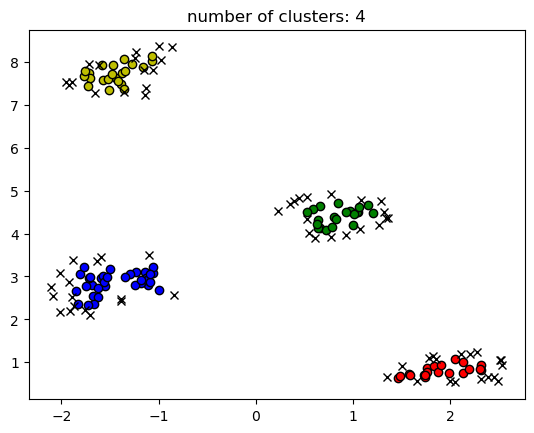

In [5]:
# clustering
db = DBSCAN(eps=0.3, min_samples=10).fit(X)
core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True
labels = db.labels_

n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)

unique_labels = set(labels)
colors = ['y', 'b', 'g', 'r']
print(colors)
for k, col in zip(unique_labels, colors):
    if k == -1:
       
        col = 'k'

    class_member_mask = (labels == k)

    xy = X[class_member_mask & core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=col,
             markeredgecolor='k',
             markersize=6)

    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'x', markerfacecolor=col,
             markeredgecolor='k',
             markersize=6)

plt.title('number of clusters: %d' % n_clusters_)
plt.show()

In [6]:
# evaluation
from sklearn import metrics
sc = metrics.silhouette_score(X, labels)
print("Silhouette Coefficient:%0.2f" % sc)
ari = metrics.adjusted_rand_score(y_true, labels)
print("Adjusted Rand Index: %0.2f" % ari)

Silhouette Coefficient:0.13
Adjusted Rand Index: 0.31


## Wholesale dataset

In [7]:
# load dataset
wholesale_df = pd.read_csv("../Datasets/Wholesale customers data.csv")

wholesale_df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [8]:
wholesale_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [9]:
wholesale_df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [10]:
wholesale_df.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

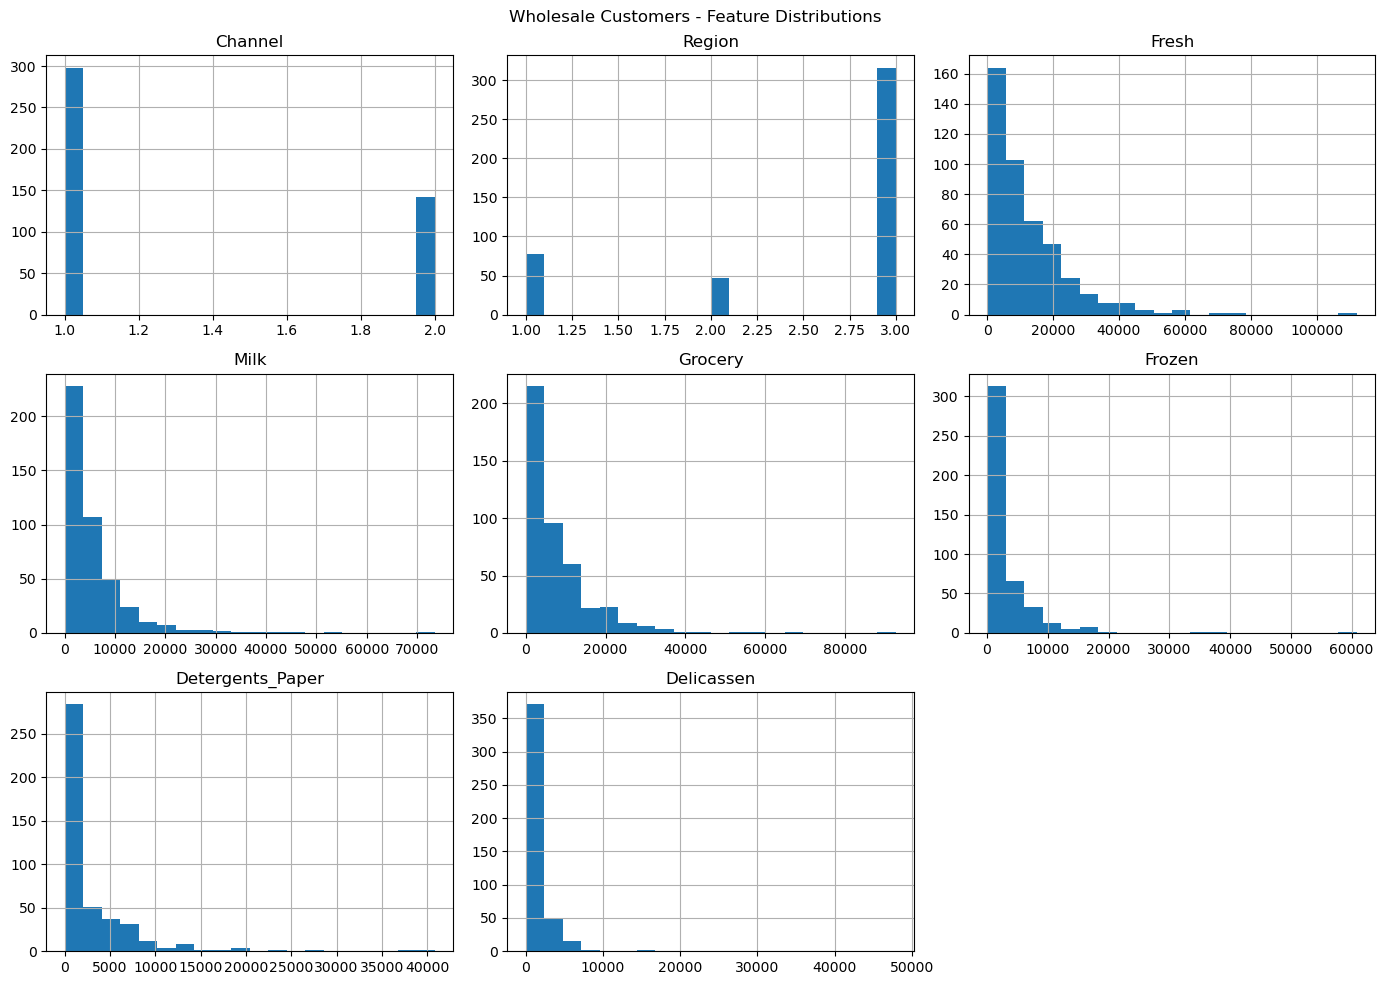

In [11]:
# feature distributions
wholesale_df.hist(figsize=(14, 10), bins=20)
plt.suptitle("Wholesale Customers - Feature Distributions")
plt.tight_layout()
plt.show()

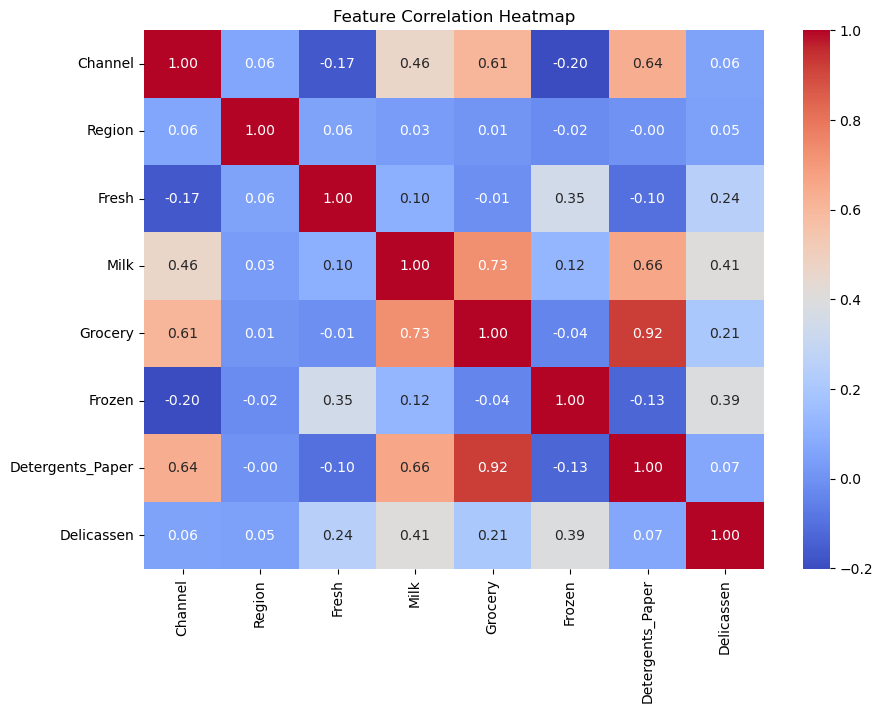

In [12]:
# correlation
plt.figure(figsize=(10, 7))

sns.heatmap(wholesale_df.corr(numeric_only=True),annot=True,cmap="coolwarm",fmt=".2f")

plt.title("Feature Correlation Heatmap")
plt.show()

In [13]:
# preprocessing
# select features
X = wholesale_df.drop(columns=['Channel', 'Region']).copy()

X.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


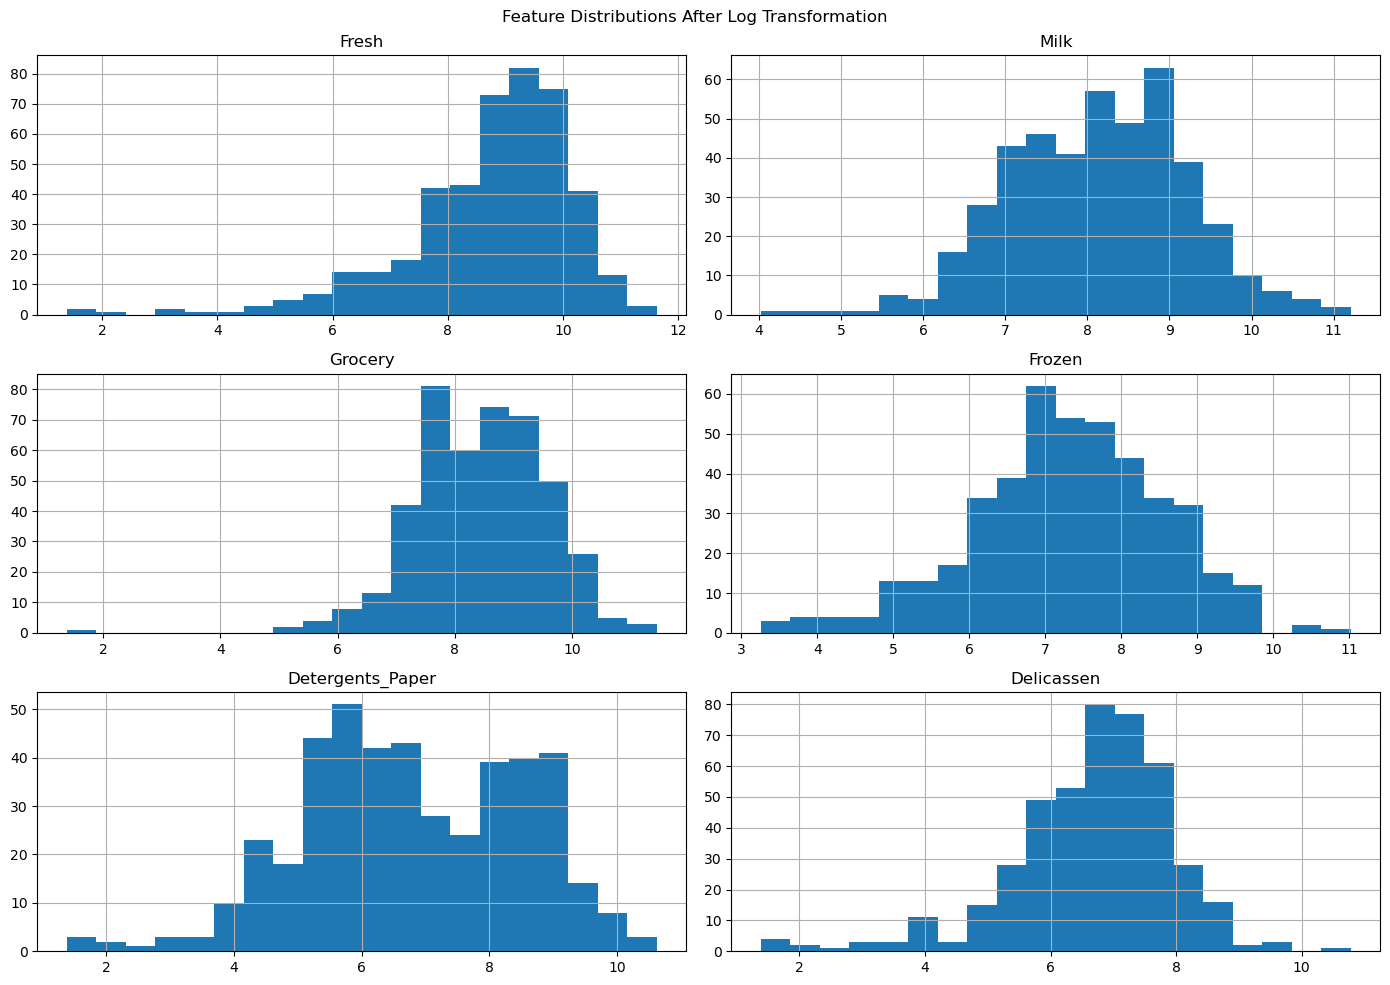

In [14]:
# handle skewness
X_log = np.log1p(X)

X_log.hist(figsize=(14, 10), bins=20)
plt.suptitle("Feature Distributions After Log Transformation")
plt.tight_layout()
plt.show()

In [15]:
# feature scaling
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

X_scaled = pd.DataFrame(X_scaled,columns=X.columns,index=X.index)

X_scaled.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.486184,0.976299,0.440155,-1.509250,0.644143,0.408966
1,0.087889,0.990956,0.652171,0.134052,0.766043,0.627926
2,0.016356,0.891151,0.454687,0.376899,0.804405,1.776833
3,0.517477,-0.957973,-0.084792,1.141574,-0.328712,0.633133
4,0.880631,0.439662,0.395847,0.757322,0.404939,1.456588


In [16]:
# Modelling
dbscan = DBSCAN(eps=0.5, min_samples=5)

clusters = dbscan.fit_predict(X_scaled)

wholesale_df['Cluster'] = clusters

wholesale_df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
0,2,3,12669,9656,7561,214,2674,1338,-1
1,2,3,7057,9810,9568,1762,3293,1776,0
2,2,3,6353,8808,7684,2405,3516,7844,-1
3,1,3,13265,1196,4221,6404,507,1788,-1
4,2,3,22615,5410,7198,3915,1777,5185,-1


In [17]:
# cluster distribution
wholesale_df['Cluster'].value_counts().sort_index()

Cluster
-1    435
 0      5
Name: count, dtype: int64

In [18]:
n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
n_noise = list(clusters).count(-1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("Noise percentage:", round((n_noise / len(clusters)) * 100, 2), "%")

Number of clusters: 1
Number of noise points: 435
Noise percentage: 98.86 %


In [19]:
# evaluation
mask = clusters != -1
X_eval = X_scaled[mask]
clusters_eval = clusters[mask]

if len(set(clusters_eval)) > 1:
    silhouette = silhouette_score(X_eval, clusters_eval)
    db_index = davies_bouldin_score(X_eval, clusters_eval)
    ch_score = calinski_harabasz_score(X_eval, clusters_eval)

    print("Silhouette Score:", silhouette)
    print("Davies-Bouldin Index:", db_index)
    print("Calinski-Harabasz Score:", ch_score)
else:
    print("Evaluation requires at least two non-noise clusters.")

Evaluation requires at least two non-noise clusters.


In [20]:
print("Total data points:", len(clusters))
print("Clustered points:", sum(mask))
print("Noise points:", sum(~mask))
print("Noise percentage:", round((sum(~mask) / len(clusters)) * 100, 2), "%")

Total data points: 440
Clustered points: 5
Noise points: 435
Noise percentage: 98.86 %


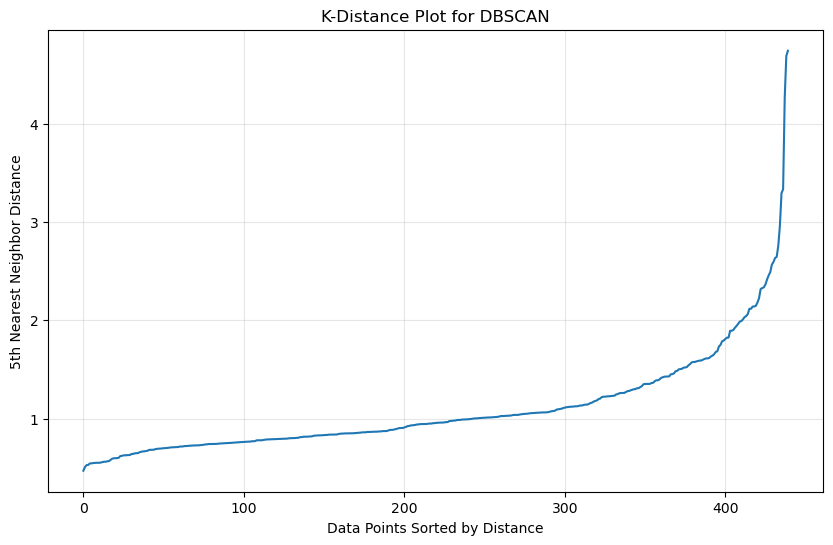

In [21]:
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 6))
plt.plot(k_distances)
plt.title("K-Distance Plot for DBSCAN")
plt.xlabel("Data Points Sorted by Distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.grid(alpha=0.3)
plt.show()

In [22]:
results = []

for eps in [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]:
    for min_samples in [3, 5, 8, 10, 15]:
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = np.sum(labels == -1)

        if n_clusters >= 2:
            mask = labels != -1
            X_eval = X_scaled.iloc[mask]
            labels_eval = labels[mask]

            silhouette = silhouette_score(X_eval, labels_eval)
            db_index = davies_bouldin_score(X_eval, labels_eval)
            ch_score = calinski_harabasz_score(X_eval, labels_eval)
        else:
            silhouette = np.nan
            db_index = np.nan
            ch_score = np.nan

        results.append({
            'Epsilon': eps,
            'Min Samples': min_samples,
            'Clusters': n_clusters,
            'Noise Points': n_noise,
            'Noise %': round(n_noise / len(labels) * 100, 2),
            'Silhouette Score': silhouette,
            'Davies-Bouldin Index': db_index,
            'Calinski-Harabasz Score': ch_score
        })

dbscan_results = pd.DataFrame(results)
dbscan_results.round(4)

,Epsilon,Min Samples,Clusters,Noise Points,Noise %,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,0.5,3,8,396,90.00,0.4175,0.7950,72.1021
1,0.5,5,1,435,98.86,NaN,NaN,NaN
2,0.5,8,0,440,100.00,NaN,NaN,NaN
3,0.5,10,0,440,100.00,NaN,NaN,NaN
4,0.5,15,0,440,100.00,NaN,NaN,NaN
5,1.0,3,6,91,20.68,-0.1016,1.1109,7.6233
6,1.0,5,1,124,28.18,NaN,NaN,NaN
7,1.0,8,2,146,33.18,0.2450,0.8401,20.2695
8,1.0,10,1,170,38.64,NaN,NaN,NaN
9,1.0,15,1,211,47.95,NaN,NaN,NaN


In [23]:
dbscan_final = DBSCAN(eps=1.5, min_samples=3)

final_clusters = dbscan_final.fit_predict(X_scaled)

wholesale_df['DBSCAN_Cluster'] = final_clusters

wholesale_df['DBSCAN_Cluster'].value_counts().sort_index()

DBSCAN_Cluster
-1     35
 0    402
 1      3
Name: count, dtype: int64

In [24]:
mask = final_clusters != -1

X_eval = X_scaled[mask]
labels_eval = final_clusters[mask]

print("Clusters:", len(set(labels_eval)))
print("Noise points:", np.sum(~mask))
print("Noise percentage:", round(np.mean(~mask) * 100, 2), "%")

print("\nSilhouette Score:", silhouette_score(X_eval, labels_eval))
print("Davies-Bouldin Index:", davies_bouldin_score(X_eval, labels_eval))
print("Calinski-Harabasz Score:", calinski_harabasz_score(X_eval, labels_eval))

Clusters: 2
Noise points: 35
Noise percentage: 7.95 %

Silhouette Score: 0.3973477184892678
Davies-Bouldin Index: 0.6409168878815938
Calinski-Harabasz Score: 12.674176729272327


In [25]:
# PCA 
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.44077752 0.27194917]
Total explained variance: 0.7127266893428754


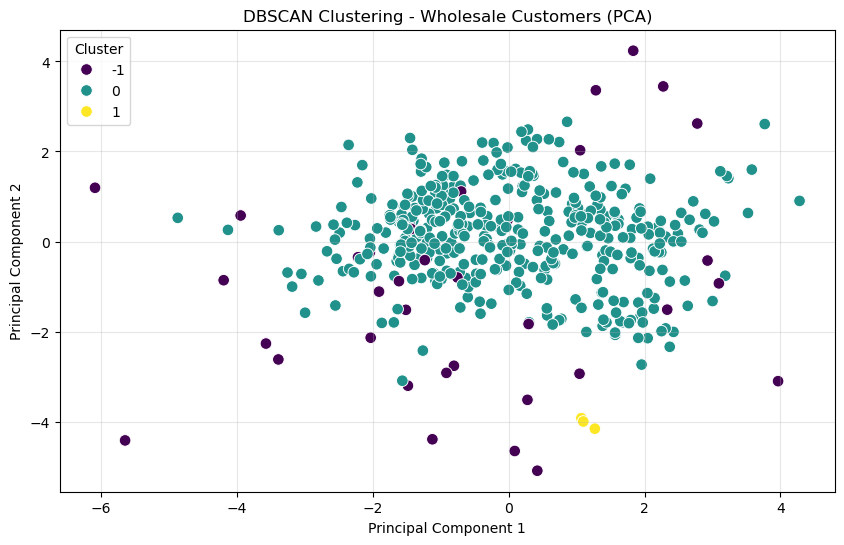

In [26]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x=X_pca[:, 0],y=X_pca[:, 1],hue=final_clusters,palette='viridis',s=70)

plt.title("DBSCAN Clustering - Wholesale Customers (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.show()

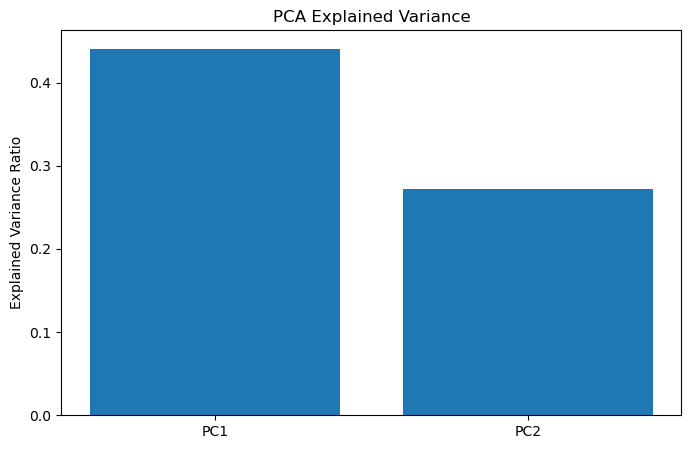

In [27]:
plt.figure(figsize=(8, 5))

plt.bar(
    ['PC1', 'PC2'],
    pca.explained_variance_ratio_
)

plt.title("PCA Explained Variance")
plt.ylabel("Explained Variance Ratio")
plt.show()

In [28]:
cluster_profiles = wholesale_df[
    wholesale_df['DBSCAN_Cluster'] != -1
].groupby('DBSCAN_Cluster')[
    X.columns
].mean().round(2)

cluster_profiles

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
DBSCAN_Cluster,,,,,,
0,11843.79,5675.01,7650.66,2893.98,2841.90,1372.33
1,52.33,2498.67,14263.33,126.67,4530.33,129.67


## Conclusion – DBSCAN

DBSCAN was applied to the Wholesale Customers dataset to identify customer segments based on their spending patterns.

The final model used:
- **Epsilon:** 1.5
- **Min Samples:** 3
- **Number of clusters:** 2
- **Noise points:** 35 (7.95%)

Model evaluation produced:
- **Silhouette Score:** 0.3973
- **Davies-Bouldin Index:** 0.6409
- **Calinski-Harabasz Score:** 12.6742

PCA reduced the six spending features to two principal components, retaining 71.27% of the total variance for visualization.

Cluster profiling revealed two distinct spending patterns: customers with higher fresh-product spending and customers focused more on groceries and household supplies.

Overall, DBSCAN successfully identified two customer groups and detected potential outliers without requiring the number of clusters to be specified beforehand. However, its performance was sensitive to parameter selection, and the identified groups should be interpreted in the context of the dataset.

## Iris

In [32]:
# load dataset
from sklearn.datasets import load_iris

iris = load_iris()

iris_df = pd.DataFrame(iris.data,columns=iris.feature_names)

print(iris_df.shape)
iris_df.head()

(150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [33]:
iris_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [34]:
iris_df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [35]:
# preprocessing
X_iris = iris_df.copy()

X_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [36]:
# scaling
scaler_iris = StandardScaler()

X_iris_scaled = scaler_iris.fit_transform(X_iris)

X_iris_scaled = pd.DataFrame(X_iris_scaled,columns=X_iris.columns)

X_iris_scaled.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


In [37]:
X_iris_scaled.describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,-0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-1.87,-2.43,-1.57,-1.45
25%,-0.90,-0.59,-1.23,-1.18
50%,-0.05,-0.13,0.34,0.13
75%,0.67,0.56,0.76,0.79
max,2.49,3.09,1.79,1.71


In [38]:
# modelling
dbscan_iris = DBSCAN(eps=0.5, min_samples=5)

iris_clusters = dbscan_iris.fit_predict(X_iris_scaled)

iris_df['Cluster'] = iris_clusters

iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [39]:
# cluster distribution
iris_df['Cluster'].value_counts().sort_index()

Cluster
-1    34
 0    45
 1    71
Name: count, dtype: int64

In [40]:
# Number of clusters and noise points
n_clusters = len(set(iris_clusters)) - (1 if -1 in iris_clusters else 0)
n_noise = np.sum(iris_clusters == -1)

print("Number of clusters:", n_clusters)
print("Noise points:", n_noise)
print("Noise percentage:", round(n_noise / len(iris_clusters) * 100, 2), "%")

Number of clusters: 2
Noise points: 34
Noise percentage: 22.67 %


In [ ]:
# Eva